N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64
Veri boyutu: (2200, 8)
    N   P   K  temperature   humidity        ph    rainfall label
0  90  42  43    20.879744  82.002744  6.502985  202.935536  rice
1  85  58  41    21.770462  80.319644  7.038096  226.655537  rice
2  60  55  44    23.004459  82.320763  7.840207  263.964248  rice
3  74  35  40    26.491096  80.158363  6.980401  242.864034  rice
4  78  42  42    20.130175  81.604873  7.628473  262.717340  rice
Model doğruluk oranı: 0.9931818181818182

Detaylı Rapor:
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        23
      banana       1.00      1.00      1.00        21
   blackgram       1.00      1.00      1.00        20
    chickpea       1.00      1.00      1.00        26
     coconut       1.00      1.00      1.00        27
      coffee       1.00      1.00      1.00       

/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


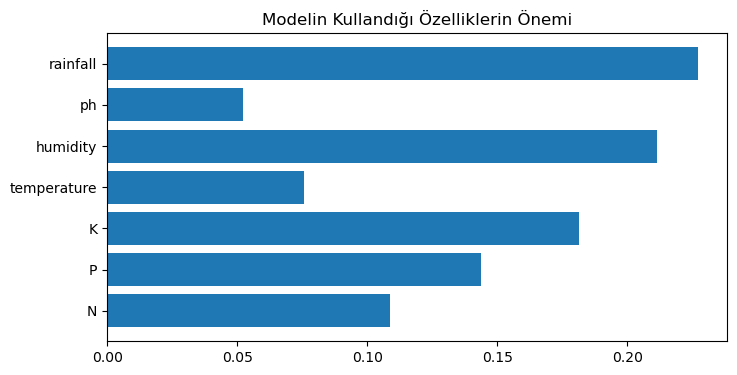

In [4]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
import joblib


veri = pd.read_csv("Crop_recommendation.csv")
print(veri.isnull().sum())



pd.read_csv("Crop_recommendation.csv")




print("Veri boyutu:", veri.shape)
print(veri.head())


X = veri.drop("label", axis=1)
y = veri["label"]


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)


joblib.dump(model, 'trained_model.pkl')
print("Model başarıyla kaydedildi: trained_model.pkl")


tahmin = model.predict(X_test)


print("Model doğruluk oranı:", accuracy_score(y_test, tahmin))
print("\nDetaylı Rapor:")
print(classification_report(y_test, tahmin))


ornek_veri = [[90, 42, 43, 20.8, 82.0, 6.5, 202.9]]  
tahmin_sonuclari = model.predict(ornek_veri)
print("\nBu değerlere uygun ürün:", tahmin_sonuclari[0])


plt.figure(figsize=(8,4))
plt.barh(X.columns, model.feature_importances_)
plt.title("Modelin Kullandığı Özelliklerin Önemi")
plt.show()

In [1]:
import pandas as pd
import random

df = pd.read_csv("Crop_recommendation.csv")

def generate_bad_data(num_samples=500):
    bad_data = []
    print(f"{num_samples} adet uygunsuz veri üretiliyor...")
    
    for _ in range(num_samples):
       
        temp = random.choice([random.uniform(-20, 5), random.uniform(50, 70)])
        
        ph = random.choice([random.uniform(0, 3.5), random.uniform(9.5, 14)])
        
        humidity = random.choice([random.uniform(0, 10), random.uniform(100, 120)])
        
        N = random.randint(0, 150)
        P = random.randint(0, 150)
        K = random.randint(0, 150)
        rainfall = random.uniform(0, 300)
        
        bad_data.append([N, P, K, temp, humidity, ph, rainfall, 'unsuitable'])
        
    return pd.DataFrame(bad_data, columns=df.columns)

kotu_veri_df = generate_bad_data(500) 
yeni_df = pd.concat([df, kotu_veri_df], ignore_index=True)

yeni_df = yeni_df.sample(frac=1).reset_index(drop=True)

yeni_df.to_csv("Crop_recommendation_updated.csv", index=False)

print("\nİŞLEM TAMAM! ")
print(f"Eski Veri Sayısı: {len(df)}")
print(f"Yeni Veri Sayısı: {len(yeni_df)}")
print("Yeni dosya adı: 'Crop_recommendation_updated.csv'")

500 adet uygunsuz veri üretiliyor...

İŞLEM TAMAM! 
Eski Veri Sayısı: 2200
Yeni Veri Sayısı: 2700
Yeni dosya adı: 'Crop_recommendation_updated.csv'


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import joblib

veri = pd.read_csv("Crop_recommendation_updated.csv")

X = veri.drop("label", axis=1)
y = veri["label"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Model eğitiliyor (Bu işlem veriye göre 10-20 saniye sürebilir)...")
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

tahmin = model.predict(X_test)
basari = accuracy_score(y_test, tahmin)
print(f"Model Başarısı: %{basari*100:.2f}")

joblib.dump(model, 'trained_model.pkl')
print("Model kaydedildi: 'trained_model.pkl'")